<a href="https://colab.research.google.com/github/vib-hu/building-micrograd/blob/main/micrograd_from_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [283]:
import math
import numpy as np
import matplotlib.pyplot as plt

In [284]:
def f(x):
  return 3*x**2-4*x+20

In [285]:
f(3.0)

35.0

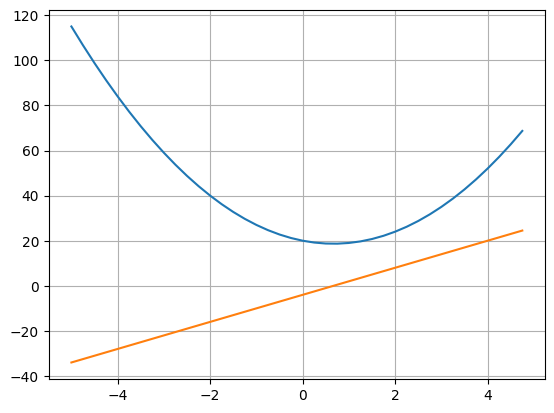

In [286]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
ys1 = 6*xs - 4

plt.figure()
plt.grid(True)
plt.plot(xs, ys)
plt.plot(xs, ys1)

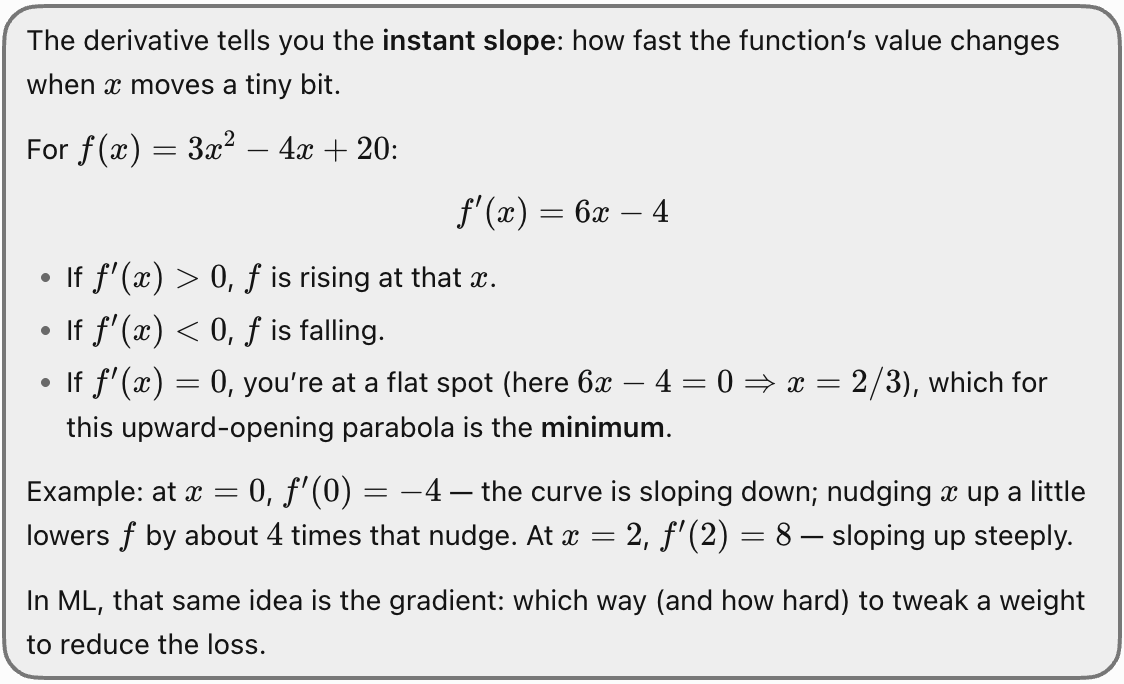

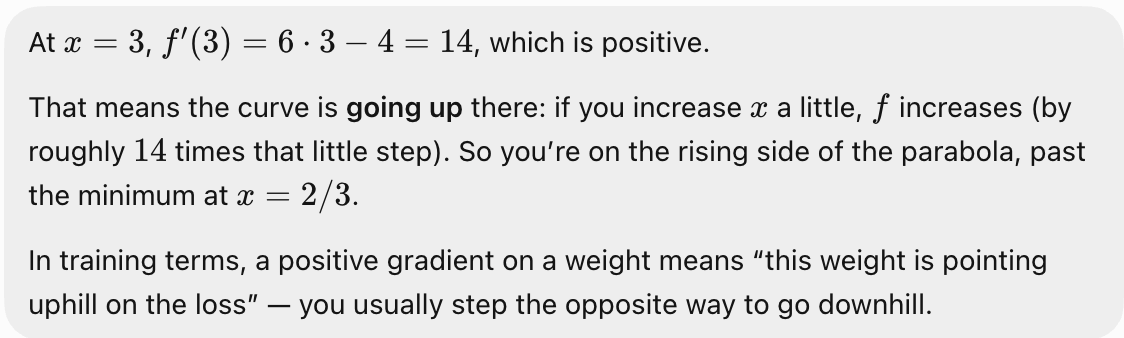

In [287]:
h = 0.00001
x = -3.0
(f(x+h) - f(x))/h # This is derivative

-21.999970000052823

In [288]:
# Complex case
a = 2.0
b = -3.0
c = 10.0

d = a*b+c
print(d)

4.0


In [289]:
h = 0.0001

#inputs
a = 2.0
b = -3.0
c = 10.0
d1 = a*b+c
d2 = (a+h)*b+c
derivative = (d2-d1)/h # slop or derivative
print(derivative)

-3.000000000010772


In [290]:
class Value:
  def __init__(self, data, _children=(), _op ='', label =''):
    self.data = data
    self.grad = 0
    self._prev = set(_children)
    self._backward = lambda: None
    self._op = _op
    self.label = label

  def __repr__(self):
    return f"value(data={self.data})"

  def __add__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data + other.data, (self, other), '+', )

    def _backward():
      self.grad += 1.0 * out.grad
      other.grad += 1.0 * out.grad
    out._backward = _backward
    return out

  def __truediv__(self, other):
    return self * (other**-1)

  def __mul__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data * other.data, (self, other), '* ')
    def _backward():
      self.grad += other.data*out.grad
      other.grad += self.data*out.grad
    out._backward = _backward
    return out

  def __pow__(self, other):
    assert isinstance(other, (int, float)), "only int/float powers"
    out = Value(self.data**other, (self,), f'**{other}')
    def _backward():
        self.grad += (other * self.data**(other-1)) * out.grad
    out._backward = _backward
    return out

  def tanh(self):
    x = self.data
    t = (math.exp(2*x)-1)/(math.exp(2*x)+1)
    out = Value(t, (self,), 'tanh')
    def _backward():
      self.grad += (1-t**2)*out.grad
    out._backward = _backward
    return out

  def __rmul__(self, other):
    return self * other

  def __radd__(self, other):
    return self + other

  def __sub__(self, other):
    return self + (-other)

  def __rsub__(self, other):
    return other + (-self)

  def exp(self):
    x = self.data
    out = Value(math.exp(x), (self,), 'exp')
    def _backward():
      self.grad += out.data * out.grad
    out._backward = _backward
    return out

  def backward(self):
    topo =[]
    visited = set()
    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self)
    self.grad = 1.0
    for node in reversed(topo):
      node._backward()


In [291]:
a = Value(2.0, 'a')
b = Value(-3.0, 'b')
c = Value(10.0, 'c')
e = a*b; e.label = 'e'
d = e+c; d.label = 'd'
f = Value(-2.0, label = 'f')
L = d*f; L.label = 'L'
f

value(data=-2.0)

In [292]:
L.grad = 1.0 #dL/dL = 1.00
f.grad = 4.00 #dL/df = d = 4.00
d.grad = -2.00 #dL/dd = f = -2.00
#Using chain rule for dL/dc
#The plus node passes the gradient through unchanged (×1), the multiply node
#scales it by the other input’s value, and chaining these local steps backward
#from L gives every variable’s gradient.
#dL/dc = (dL/dd)*(dd/dc) = f*1 because e is constant so it's 0 and dd/dc for c is 1.
c.grad = -2.00 # f*1
e.grad = -2.00 # dL/de = (dL/dd)*(dd/de) = f*1 = f
# dL/da = (dL/dd)*(dd/de)*(de/da) = (f)*(1)*(b) = -2.00*-3.00
a.grad = 6.00
# dL/db = (dL/dd)*(dd/de)*(de/db) = (f)*(1)*(a) = -2.00*2.00
b.grad = -4.00

*   To make L go up: **x.data += step * x.grad (gradient ascent)**
*   To make L go down (training, since L is loss): **x.data -= step * x.grad (gradient descent)**
*   One formula works for every variable regardless of gradient sign, because the sign is already inside x.grad. The -= just means “move opposite to the slope.”
*   Keep step small, because the gradient is only accurate for tiny changes.
*   Example with L = d * f
*   d = 4, f = -2, L = -8, and the gradients were d.grad = -2, f.grad = 4.
*   Say we want L to go down (more negative). Use step = 0.01:
*   d.data = 4  - 0.01 * (-2) = 4 + 0.02 = 4.02
*   f.data = -2 - 0.01 * (4)  = -2 - 0.04 = -2.04
*   Recompute: L = 4.02 × -2.04 = -8.2008
*   L went from -8 to -8.2008, so it went down.

In [293]:
a.data += 0.01*a.grad
b.data += 0.01*b.grad
c.data += 0.01*c.grad
f.data += 0.01*f.grad

print(f"before L: {L}")
e = a*b
d = e+c
L = d*f
print(f"after L: {L}")


before L: value(data=-8.0)
after L: value(data=-7.286496)


In [294]:
def lol():
  h = 0.00001

  a = Value(2.0, 'a')
  b = Value(-3.0, 'b')
  c = Value(10.0, 'c')
  e = a*b; e.label = 'e'
  d = e+c; d.label = 'd'
  f = Value(-2.0, label = 'f')
  L = d*f; L.label = 'L'
  L1 = L.data

  a = Value(2.0, 'a')
  a.data += h
  b = Value(-3.0, 'b')
  c = Value(10.0, 'c')
  e = a*b; e.label = 'e'
  d = e+c; d.label = 'd'
  f = Value(-2.0, label = 'f')
  L = d*f; L.label = 'L'
  L2 = L.data

  print((L2-L1)/h)
lol()


6.000000000128124


The hyperbolic tangent function, denoted as tanh(x) is a hyperbolic function that is the analogue of the standard trigonometric tangent.

**Why tanh beats sigmoid for hidden layers**

Zero-centered outputs. If every activation is positive, as with sigmoid, the gradients for all of a neuron's weights share the same sign. Updates then zig-zag toward the optimum. tanh outputs are both positive and negative, which gives better-conditioned updates and faster convergence.
LeCun's Efficient BackProp (1998) makes this argument.
Stronger gradients. The peak derivative is 1 instead of 0.25, so signals shrink more slowly as they pass back through layers.


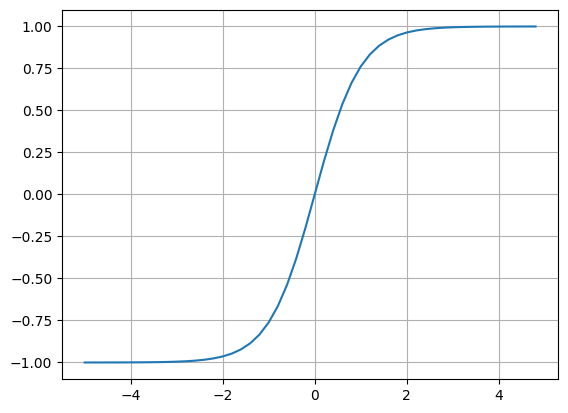

In [295]:
plt.plot(np.arange(-5,5,0.2), np.tanh(np.arange(-5,5,0.2)));
plt.grid()

In [296]:
# inputs x1 and x2
x1 = Value(2.0, label ='x1')
x2 = Value(0.0, label ='x2')
#Weights
w1 = Value(-3.0, label ='w1')
w2 = Value(1.0, label ='w2')
#Bias
b = Value(6.7, label ='b')

x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = "x1*w1 + x2*w2"
n = x1w1x2w2 +b; n.label = 'n'
o = n.tanh()

In [297]:
import torch
x1 = torch.Tensor([2.0]).double(); x1.requires_grad = True
x2 = torch.Tensor([0.0]).double(); x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double(); w1.requires_grad = True
w2 = torch.Tensor([1.0]).double(); w2.requires_grad = True
b = torch.Tensor([6.88137]).double(); b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print("-------")
print('x1', x2.grad.item())
print('x2', x2.grad.item())
print('w1', w1.grad.item())
print('w2', w2.grad.item())

0.7071050214706146
-------
x1 0.5000024886110417
x2 0.5000024886110417
w1 1.0000049772220834
w2 0.0


In [298]:
x2.grad

tensor([0.5000], dtype=torch.float64)

In [301]:
import random
class Nueron:
  def __init__(self, nputs):
    self.w = [Value(random.uniform(-1,1)) for _ in range(nputs)]
    self.b = Value(random.uniform(-1,1))

  def __call__(self, x):
    #w*x+b
    act = sum(wi*xi for wi,xi in zip(self.w,x)) + self.b
    out = act.tanh()
    return out

  def parameters(self):
    return self.w + [self.b]

class Layer:
  def __init__(self, inputs_per_nueron, nuerons_per_layer):
    self.neurons = [Nueron(inputs_per_nueron) for _ in range(nuerons_per_layer)]

  def __call__(self, x):
    outs = [n(x) for n in self.neurons]
    return outs[0] if len(outs)==1 else outs

  def parameters(self):
    return [parameter for nueron in self.neurons for parameter in nueron.parameters()]

class MLP:
  def __init__(self, inputs_per_nueron, nuerons_per_layer):
    sz = [inputs_per_nueron]+nuerons_per_layer
    self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nuerons_per_layer))]

  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)
    return x

  def parameters(self):
    return [parameter for layer in self.layers for parameter in layer.parameters()]

x= [2.0, 3.0, -1.0]
n = MLP(3, [4,4,1])
print(n(x))

value(data=0.481404304152123)


In [304]:
len(n.parameters())

41

In [ ]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0] # desired target
ypred = [n(x) for x in xs]
ypred

In [ ]:
# Calculate loss function
loss = sum([(yout-ygt)**2 for ygt,yout in zip(ys, ypred)])
loss

In [ ]:
loss.backward()
n.layers[0].neurons[0].w[0].grad